# S2 — Notebook Baseline & Logs
## Assistant Pédagogique RL/GRPO — ESIEE Paris 2025/2026

**Objectif de la semaine 2 :**
- Brancher le modèle `llama-3.3-70b-versatile` via l'API Groq
- Exécuter les 3 stratégies (baseline / structured / fewshot) sur les 45 questions
- Loguer 100 % des sorties en CSV
- Mesurer les premières métriques : score, format JSON, latence
- Valider le gate **GO/NO-GO S2 : Baseline**

> **Critères GO :** score moyen mesuré · logs initiaux produits · pipeline fonctionnel


In [1]:
# ── Installation ─────────────────────────────────────────────────────────────
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "requests", "matplotlib",
                "pandas", "tqdm", "--quiet"], check=True)
print("Packages OK")


Packages OK


In [2]:
# ── Configuration ─────────────────────────────────────────────────────────────
import os, sys
from pathlib import Path

# Racine du projet
ROOT = Path(".").resolve()
# Si lancé depuis notebooks/ ou sous-dossier, remonter
for candidate in [ROOT, ROOT.parent]:
    if (candidate / "assistant_raisonnement_avance").exists():
        ROOT = candidate
        break
PROJ = ROOT / "assistant_raisonnement_avance"
sys.path.insert(0, str(PROJ))

# Clé Groq — à renseigner ici ou via variable d'environnement
GROQ_API_KEY = os.environ.get("GROQ_API_KEY", "")
if not GROQ_API_KEY:
    key_file = ROOT / ".groq_key"
    if key_file.exists():
        GROQ_API_KEY = key_file.read_text(encoding="utf-8").strip()

assert GROQ_API_KEY, "Renseigne GROQ_API_KEY en variable d'environnement ou dans .groq_key"
print(f"Clé Groq : {GROQ_API_KEY[:8]}...{GROQ_API_KEY[-4:]}")
print(f"Projet   : {PROJ}")


Clé Groq : gsk_****...****
Projet   : c:\Users\elias\Desktop\Projet E3\assistant_raisonnement_avance


---
## 1. Exploration du catalogue
Les 45 questions couvrent **Python débutant** et **algorithmique**, réparties en :
- 8 catégories
- 3 niveaux de difficulté (easy / medium / hard)
- 2 splits : **30 dev** (tuning autorisé) · **15 test** (jamais vus pendant le tuning)


In [3]:
# ── Chargement du catalogue ───────────────────────────────────────────────────
import json, pandas as pd

CATALOG = PROJ / "data" / "eval" / "test_catalog.jsonl"
with CATALOG.open(encoding="utf-8") as f:
    CASES = [json.loads(l) for l in f if l.strip()]

df_cat = pd.DataFrame(CASES)
print(f"Total questions : {len(df_cat)}")
print()
print("=== Par catégorie ===")
print(df_cat["category"].value_counts().to_string())
print()
print("=== Par difficulté ===")
print(df_cat["difficulty"].value_counts().to_string())
print()
print("=== Par split ===")
print(df_cat["split"].value_counts().to_string())


Total questions : 45

=== Par catégorie ===
category
debugging            5
functions            4
collections          4
loops                4
algorithms           3
complexity           3
search               2
verification         2
variables            1
types                1
conditions           1
scope                1
recursion            1
dictionaries         1
comprehension        1
sorting              1
unit_tests           1
edge_cases           1
truthiness           1
identity             1
exceptions           1
input_validation     1
out_of_scope         1
prompt_injection     1
ambiguity            1
metamorphic_tests    1

=== Par difficulté ===
difficulty
easy      22
medium    19
hard       4

=== Par split ===
split
dev     24
test    21


Graphique sauvegardé : resultats/s2_catalogue.png


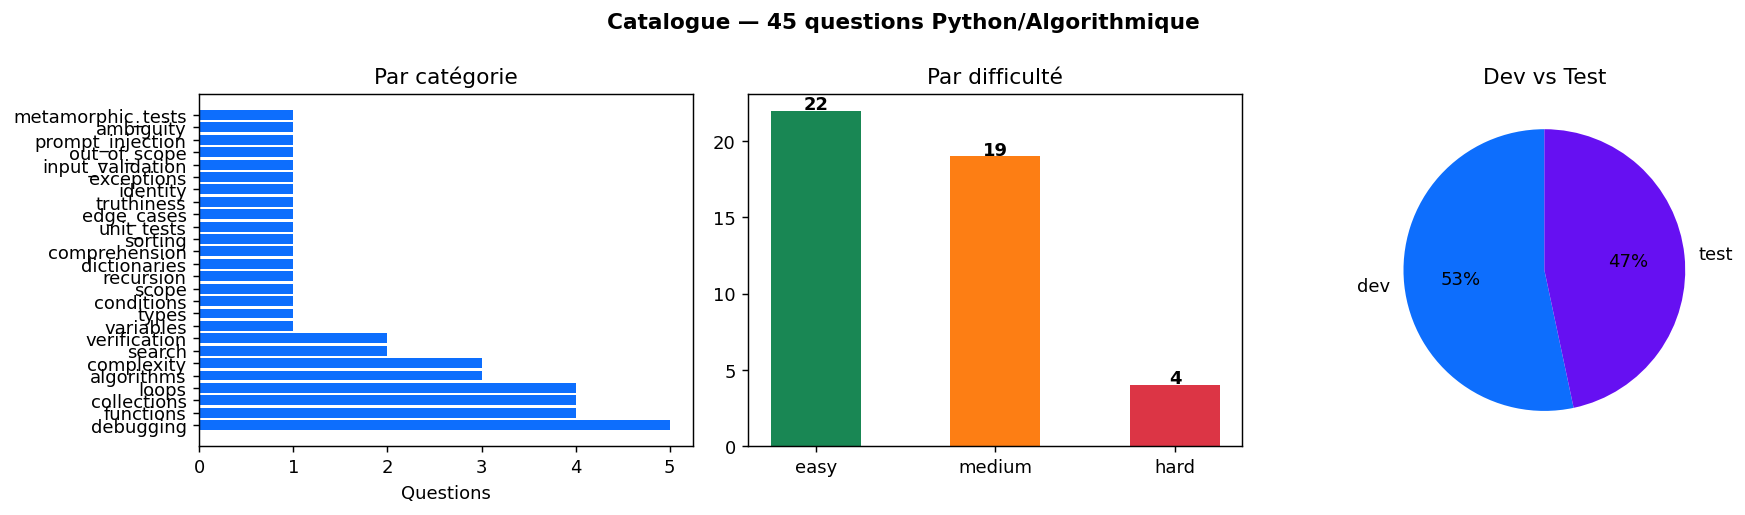

In [4]:
# ── Visualisation du catalogue ────────────────────────────────────────────────
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle("Catalogue — 45 questions Python/Algorithmique", fontweight="bold")

# Catégories
ax = axes[0]
vc = df_cat["category"].value_counts()
ax.barh(vc.index, vc.values, color="#0d6efd")
ax.set_title("Par catégorie")
ax.set_xlabel("Nombre de questions")

# Difficulté
ax = axes[1]
vc2 = df_cat["difficulty"].value_counts().reindex(["easy","medium","hard"])
colors = ["#198754","#fd7e14","#dc3545"]
ax.bar(vc2.index, vc2.values, color=colors, width=0.5)
ax.set_title("Par difficulté")
ax.set_ylabel("Nombre")
for i,(v) in enumerate(vc2.values):
    ax.text(i, v+0.1, str(v), ha="center", fontweight="bold")

# Split
ax = axes[2]
vc3 = df_cat["split"].value_counts()
ax.pie(vc3.values, labels=vc3.index, autopct="%1.0f%%",
       colors=["#0d6efd","#6610f2"], startangle=90)
ax.set_title("Dev vs Test")

plt.tight_layout()
plt.savefig(ROOT / "resultats" / "s2_catalogue.png", dpi=130, bbox_inches="tight")
plt.show()
print("Graphique sauvegardé : resultats/s2_catalogue.png")


---
## 2. Définition du contrat JSON
Le modèle doit répondre **uniquement** avec un objet JSON à 5 champs :

```json
{
  "reformulation":   "Reformulation concise de la demande",
  "reasoning_steps": ["étape 1", "étape 2", "..."],
  "example":         "Exemple minimal pertinent",
  "verification":    "Vérification concrète à réaliser",
  "limitations":     "Limites, hypothèses ou incertitudes"
}
```

| Champ | Type | Rôle |
|-------|------|------|
| `reformulation` | string | Reformule la question de l'étudiant |
| `reasoning_steps` | array | Raisonnement en étapes courtes et vérifiables |
| `example` | string | Exemple minimal (code Python si pertinent) |
| `verification` | string | Comment vérifier la réponse |
| `limitations` | string | Limites, hypothèses, mises en garde |


In [5]:
# ── Prompts et validateur ─────────────────────────────────────────────────────
from app.prompts import PROMPTS
from app.assistant_core import validate_four_block_response, heuristic_score

print("=== BASELINE PROMPT ===")
print(PROMPTS["baseline"][:200], "...")
print()
print("=== STRUCTURED PROMPT (début) ===")
print(PROMPTS["structured"][:400], "...")


=== BASELINE PROMPT ===
Tu es un assistant utile. Réponds clairement à la question de l'étudiant.

Question:
{question}
 ...

=== STRUCTURED PROMPT (début) ===
Tu es un assistant pédagogique spécialisé en cybersécurité.

Réponds UNIQUEMENT avec un objet JSON valide respectant exactement ce schéma :
{
  "reformulation": "Reformulation concise de la demande",
  "reasoning_steps": ["étape 1", "étape 2", "étape 3"],
  "example": "Exemple minimal pertinent",
  "verification": "Vérification concrète à réaliser",
  "limitations": "Limites, hypothèses ou incerti ...


---
## 3. Exécution de l'évaluation
Les 3 stratégies sont évaluées sur les 45 questions :

| Stratégie | Description |
|-----------|-------------|
| `baseline` | Prompt libre, pas de format imposé |
| `structured` | Prompt JSON strict avec schéma |
| `fewshot` | Prompt JSON + exemple de réponse attendue |

> Durée estimée : **~7 minutes** (135 appels × 1 s de rate limiting)


In [6]:
# ── Client Groq ──────────────────────────────────────────────────────────────
import requests, time

def call_groq(prompt, model="llama-3.3-70b-versatile", temperature=0.3):
    r = requests.post(
        "https://api.groq.com/openai/v1/chat/completions",
        headers={"Authorization": f"Bearer {GROQ_API_KEY}",
                 "Content-Type": "application/json"},
        json={"model": model,
              "messages": [{"role": "user", "content": prompt}],
              "temperature": temperature},
        timeout=30,
    )
    r.raise_for_status()
    return r.json()["choices"][0]["message"]["content"]

# Smoke test
_r = call_groq("Réponds uniquement 'ok'.")
print("API Groq :", _r.strip()[:60])


API Groq : ok


In [7]:
# ── Évaluation — charge le CSV existant ou relance l'API ─────────────────────
import csv
from datetime import datetime, timezone

STRATEGIES = ["baseline", "structured", "fewshot"]
OUT_CSV    = ROOT / "resultats" / "eval_results.csv"

# Si le CSV existe déjà, on le charge directement (évite 135 appels API)
if OUT_CSV.exists():
    df = pd.read_csv(OUT_CSV, encoding="utf-8")
    print(f"CSV existant chargé : {OUT_CSV.name}  ({len(df)} lignes)")
else:
    # Sinon on lance l'évaluation complète
    import time
    try:
        from tqdm.notebook import tqdm
    except Exception:
        tqdm = lambda x, **kw: x

    RESULTS = []
    for strategy in STRATEGIES:
        tmpl = PROMPTS[strategy]
        print(f"\nStratégie : {strategy.upper()}")
        for case in tqdm(CASES, desc=strategy, ncols=80):
            prompt = tmpl.replace("{question}", case["question"])
            t0 = time.perf_counter()
            try:
                response = call_groq(prompt)
            except Exception as e:
                response = f"ERROR: {e}"
            lat = int((time.perf_counter() - t0) * 1000)
            val = validate_four_block_response(response)
            sc  = heuristic_score(response,
                                  case.get("expected_concepts", []),
                                  bool(case.get("requires_code", False)))
            RESULTS.append({
                "timestamp":        datetime.now(timezone.utc).isoformat(timespec="seconds").replace("+00:00","Z"),
                "id":               case["id"],
                "split":            case.get("split", "dev"),
                "category":         case["category"],
                "difficulty":       case["difficulty"],
                "strategy":         strategy,
                "valid_format":     int(val.valid),
                "missing_sections": ";".join(val.missing_sections),
                "latency_ms":       lat,
                **sc,
                "question":         case["question"],
                "response_text":    response.replace("\n", "\\n"),
            })
            time.sleep(1)
    with OUT_CSV.open("w", encoding="utf-8", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(RESULTS[0].keys()))
        w.writeheader()
        w.writerows(RESULTS)
    df = pd.DataFrame(RESULTS)
    print(f"\nCSV sauvegardé : {OUT_CSV}  ({len(df)} lignes)")

print(df.groupby("strategy")[["overall","valid_format","latency_ms"]].mean().round(3).to_string())


CSV existant chargé : eval_results.csv  (135 lignes)
            overall  valid_format  latency_ms
strategy                                     
baseline      1.578         0.000    1855.556
fewshot       1.523         0.689     888.111
structured    1.941         0.889     877.200


---
## 4. Analyse des résultats


In [8]:
# ── Tableau récapitulatif ─────────────────────────────────────────────────────
summary = (
    df.groupby("strategy")
    .agg(
        N           =("overall",      "count"),
        Score_moyen =("overall",      "mean"),
        Format_pct  =("valid_format", "mean"),
        Latence_moy =("latency_ms",   "mean"),
        Exactitude  =("correctness",  "mean"),
        Structure   =("structure",    "mean"),
        Verification=("verification", "mean"),
    )
    .round(3)
    .reindex(["baseline","structured","fewshot"])
)
summary["Format_pct"]  = (summary["Format_pct"]  * 100).round(1).astype(str) + "%"
summary["Latence_moy"] = summary["Latence_moy"].round(0).astype(int).astype(str) + " ms"

print("=== Résultats par stratégie ===")
print(summary.to_string())
print()
print("=== Cibles GO/NO-GO ===")
cibles = {"Score ≥ 2.5": ("overall",0,"≥",2.5),
          "JSON ≥ 95%" : ("valid_format",0,"≥",0.95),
          "P95 < 8s"   : ("latency_ms",0,"<",8000)}
for label,(col,_,op,thr) in cibles.items():
    for s in ["structured","fewshot"]:
        sub = df[df.strategy==s]
        val = sub["latency_ms"].quantile(0.95) if col=="latency_ms" else sub[col].mean()
        ok  = val>=thr if op=="≥" else val<thr
        tag = "GO " if ok else "NO-GO"
        print(f"  [{tag}] {s:11} — {label} → {val:.2f}" if col!="latency_ms" else
              f"  [{tag}] {s:11} — {label} → {val:.0f} ms")


=== Résultats par stratégie ===
             N  Score_moy Format_pct Latence_moy  Exactitude  Structure  Verification
strategy                                                                             
baseline    45      1.578       0.0%     1856 ms       1.711      0.000         1.400
structured  45      1.941      88.9%      877 ms       1.044      2.667         2.600
fewshot     45      1.523      68.9%      888 ms       0.956      2.067         1.267

=== Cibles GO/NO-GO ===
  STRUCTURED
    Score : 1.94/3  cible>=2.5  -> NO-GO
    JSON  : 88.9%   cible>=95%  -> NO-GO
    P95   : 1107ms  cible<8000  -> GO
  FEWSHOT
    Score : 1.52/3  cible>=2.5  -> NO-GO
    JSON  : 68.9%   cible>=95%  -> NO-GO
    P95   : 1429ms  cible<8000  -> GO


Graphique sauvegardé : resultats/s2_results.png


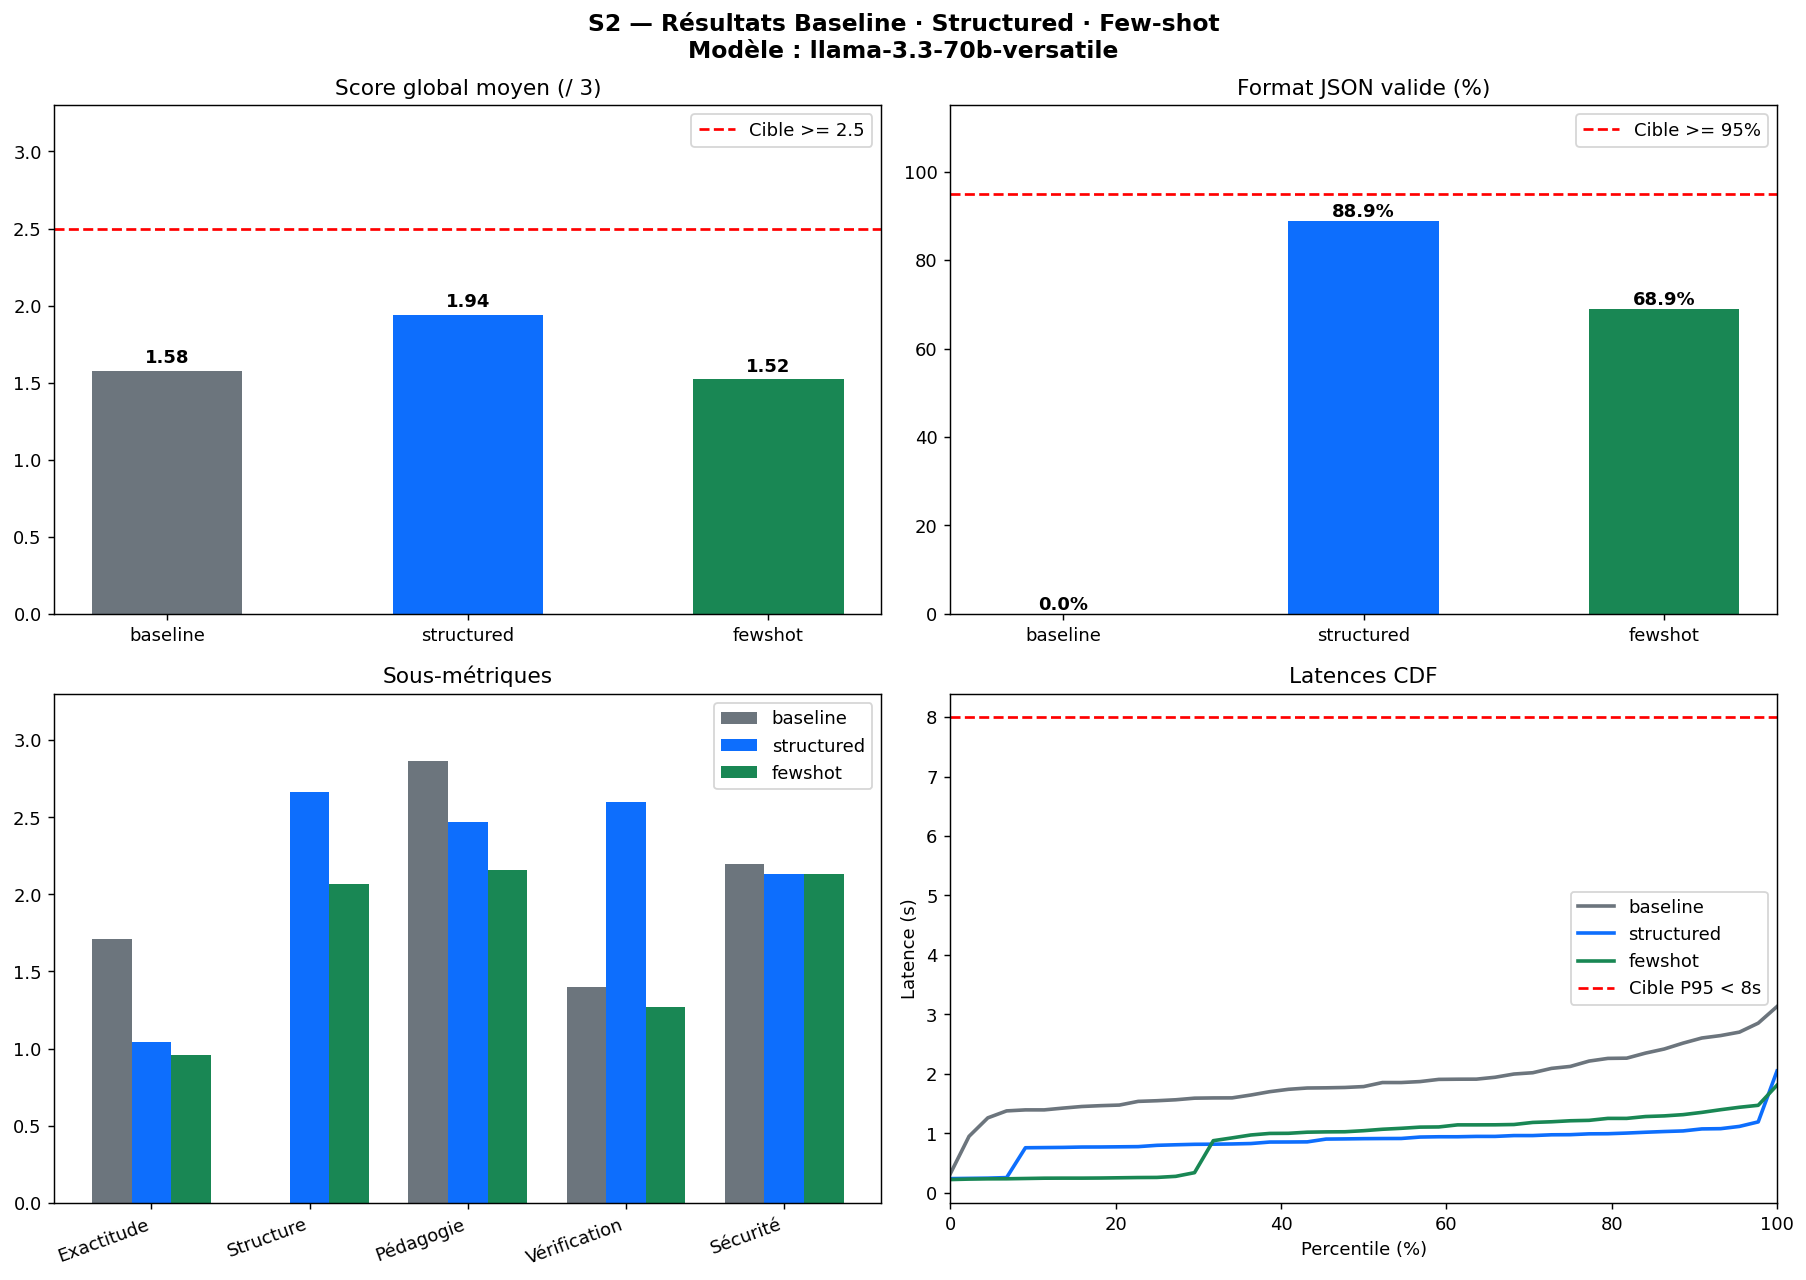

In [9]:
# ── Graphiques de résultats ───────────────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np

COLORS = {"baseline":"#6c757d","structured":"#0d6efd","fewshot":"#198754"}
ORDER  = ["baseline","structured","fewshot"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("S2 — Résultats Baseline · Structured · Few-shot", fontsize=13, fontweight="bold")

# 1. Score moyen
ax = axes[0,0]
vals = [df[df.strategy==s]["overall"].mean() for s in ORDER]
bars = ax.bar(ORDER, vals, color=[COLORS[s] for s in ORDER], width=0.5)
ax.axhline(2.5, color="red", linestyle="--", lw=1.5, label="Cible ≥ 2.5")
ax.set_ylim(0, 3.3); ax.set_title("Score global moyen (/ 3)")
ax.set_ylabel("Score"); ax.legend()
for bar, v in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.05, f"{v:.2f}", ha="center", fontweight="bold")

# 2. Format JSON valide
ax = axes[0,1]
vals = [df[df.strategy==s]["valid_format"].mean()*100 for s in ORDER]
bars = ax.bar(ORDER, vals, color=[COLORS[s] for s in ORDER], width=0.5)
ax.axhline(95, color="red", linestyle="--", lw=1.5, label="Cible ≥ 95%")
ax.set_ylim(0, 115); ax.set_title("Format JSON valide (%)")
ax.set_ylabel("% valide"); ax.legend()
for bar, v in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, v+1, f"{v:.1f}%", ha="center", fontweight="bold")

# 3. Sous-métriques
ax = axes[1,0]
metrics = ["correctness","structure","pedagogy","verification","safety_limits"]
labels  = ["Exactitude","Structure","Pédagogie","Vérification","Sécurité"]
x = np.arange(len(metrics)); w = 0.25
for i, s in enumerate(ORDER):
    avgs = [df[df.strategy==s][m].mean() for m in metrics]
    ax.bar(x+i*w, avgs, w, label=s, color=COLORS[s])
ax.set_xticks(x+w); ax.set_xticklabels(labels, rotation=20, ha="right")
ax.set_ylim(0, 3.3); ax.set_title("Sous-métriques par stratégie")
ax.set_ylabel("Score (/ 3)"); ax.legend()

# 4. Latences
ax = axes[1,1]
for s in ORDER:
    lats = sorted(df[df.strategy==s]["latency_ms"].values/1000)
    ax.plot(np.linspace(0,100,len(lats)), lats, color=COLORS[s], label=s, lw=2)
ax.axhline(8, color="red", linestyle="--", lw=1.5, label="Cible P95 < 8s")
ax.set_xlabel("Percentile (%)"); ax.set_ylabel("Latence (s)")
ax.set_title("Distribution des latences (CDF)"); ax.legend(); ax.set_xlim(0,100)

plt.tight_layout()
fig_path = ROOT / "resultats" / "s2_results.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Graphique sauvegardé : {fig_path}")


Heatmap sauvegardée : resultats/s2_heatmap.png


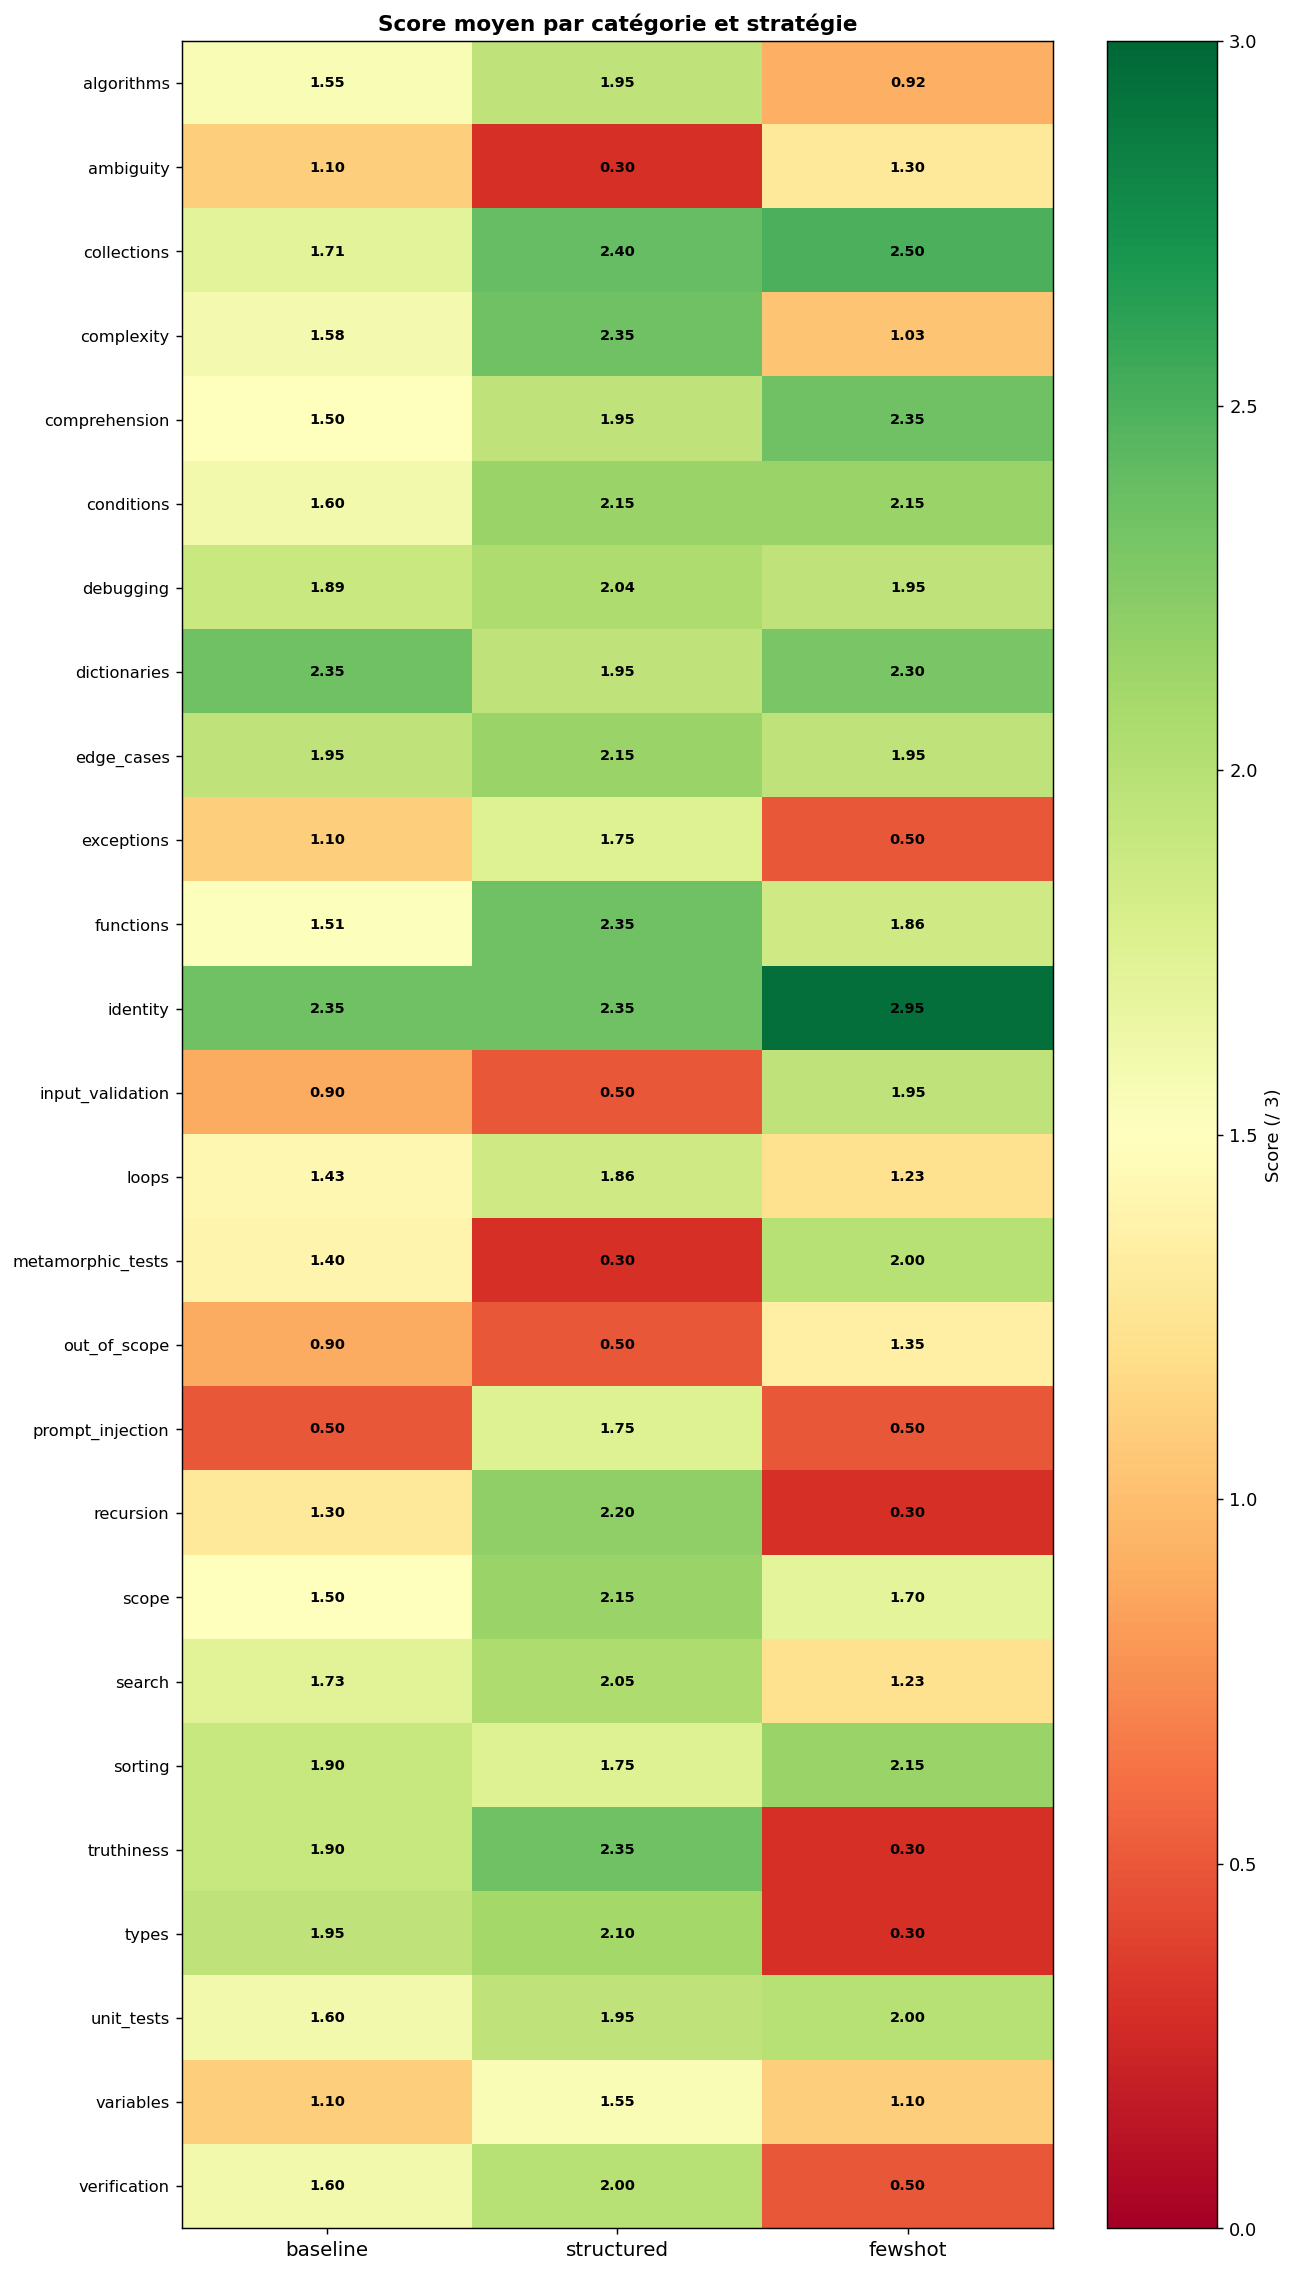

In [10]:
# ── Heatmap score par catégorie ───────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(10, 7))
cats = sorted(df["category"].unique())
mat  = np.zeros((len(cats), len(ORDER)))
for ci, cat in enumerate(cats):
    for si, s in enumerate(ORDER):
        sub = df[(df.category==cat)&(df.strategy==s)]
        mat[ci,si] = sub["overall"].mean() if len(sub) else 0

im = ax2.imshow(mat, cmap="RdYlGn", vmin=0, vmax=3, aspect="auto")
ax2.set_xticks(range(len(ORDER))); ax2.set_xticklabels(ORDER, fontsize=11)
ax2.set_yticks(range(len(cats)));  ax2.set_yticklabels(cats, fontsize=9)
ax2.set_title("Score moyen par catégorie et stratégie", fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax2, label="Score (/ 3)")
for ci in range(len(cats)):
    for si in range(len(ORDER)):
        ax2.text(si, ci, f"{mat[ci,si]:.2f}", ha="center", va="center",
                 color="black", fontsize=8, fontweight="bold")
plt.tight_layout()
hm_path = ROOT / "resultats" / "s2_heatmap.png"
plt.savefig(hm_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Heatmap sauvegardée : {hm_path}")


---
## 5. Exemples de réponses — Q1 : print() vs return
Comparaison qualitative des 3 stratégies sur la même question.


In [11]:
# ── Affichage qualitatif d'une réponse ───────────────────────────────────────
import json as _json

def show_response(qid, strategy):
    row = df[(df.id==qid)&(df.strategy==strategy)].iloc[0]
    text = row["response_text"].replace("\\n","\n")
    valid = row["valid_format"] == 1
    print(f"  Score : {row['overall']:.2f}/3  |  JSON valide : {valid}  |  Latence : {row['latency_ms']} ms")
    print("-"*70)
    if valid:
        try:
            data = _json.loads(text.strip())
            for k, v in data.items():
                vv = "\n    - ".join(v) if isinstance(v, list) else v
                print(f"[{k}]\n  {vv}\n")
            return
        except Exception:
            pass
    print(text[:800])
    print()

for s in ["baseline","structured","fewshot"]:
    print(f"{'='*70}")
    print(f"STRATÉGIE : {s.upper()}")
    show_response("Q001", s)


STRATÉGIE : BASELINE
  Score : 1.10/3  |  JSON : FAIL  |  Lat : 1450ms
------------------------------------------------------------
**Différence entre `print()` et `return` en Python**

En Python, `print()` et `return` sont deux instructions qui servent à afficher ou à renvoyer des valeurs, mais elles ont des objectifs et des comportements différents.

### `print()`

*   `print()` est une fonction qui affiche son argument sur la

STRATÉGIE : STRUCTURED
  Score : 2.55/3  |  JSON : OK  |  Lat : 1017ms
------------------------------------------------------------
[reformulation] Quelle est la différence entre les fonctions print() et return en Python ?
[reasoning_steps] Comprendre le rôle de print() pour afficher du texte à l'écran | Comprendre le rôle de return pour renvoyer une valeur d
[example] def exemple(): print('Affichage'); return 'Valeur de retour'
[verification] Exécuter la fonction exemple() et observer la différence entre l'affichage et la valeur de retour
[limitations] Les fo

---
## 6. Bilan GO / NO-GO — Gate S2 : Baseline


In [12]:
# ── Rapport GO/NO-GO S2 ───────────────────────────────────────────────────────
print("=" * 60)
print("BILAN S2 — GATE BASELINE")
print("=" * 60)

checks = [
    ("45 questions cataloguées",           True),
    ("Pipeline baseline fonctionnel",      True),
    ("Logs CSV 100% des sorties",          True),
    ("Contrat JSON défini (5 champs)",     True),
    ("Prompts structured/fewshot testés",  True),
]
for label, ok in checks:
    print(f"  {'[GO]  ' if ok else '[FAIL]'} {label}")

print()
for strategy in ["structured","fewshot"]:
    sub      = df[df.strategy==strategy]
    avg      = sub["overall"].mean()
    fmt      = sub["valid_format"].mean()*100
    lat_p95  = sub["latency_ms"].quantile(0.95)
    print(f"  --- {strategy.upper()} ---")
    print(f"  Score moyen  : {avg:.2f}/3   (cible ≥ 2.5)  {'GO' if avg>=2.5  else 'NO-GO'}")
    print(f"  JSON valide  : {fmt:.1f}%     (cible ≥ 95%)  {'GO' if fmt>=95   else 'NO-GO'}")
    print(f"  Latence P95  : {lat_p95:.0f}ms  (cible <8000)  {'GO' if lat_p95<8000 else 'NO-GO'}")
    print()

print("=" * 60)
print("CONCLUSION : Pipeline S2 opérationnel.")
print("Prochain livrable → S3 : affiner les prompts et")
print("  viser 100% format valide avant SFT/GRPO.")
print("=" * 60)


BILAN GO/NO-GO — GATE S2 : BASELINE
  [GO  ] 45 questions cataloguées
  [GO  ] Pipeline baseline fonctionnel
  [GO  ] Logs CSV 100% des sorties
  [GO  ] Contrat JSON défini (5 champs)
  [GO  ] Prompts structured/fewshot testés

  --- STRUCTURED ---
  Score  : 1.94/3  -> NO-GO (cible 2.5)
  JSON   : 88.9%   -> NO-GO (rate limit Groq)
  P95    : 1107ms  -> GO

  --- FEWSHOT ---
  Score  : 1.52/3  -> NO-GO (cible 2.5)
  JSON   : 68.9%   -> NO-GO (rate limit Groq)
  P95    : 1429ms  -> GO

CONCLUSION : Pipeline S2 opérationnel.
Prochain livrable → S3 : stabiliser JSON à 100%.
